In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# A)

In [4]:
T = 1_000
n = 10_000
delta_t = T/n

In [5]:
def gerar_normal(K = 1):
    U = np.random.uniform(size = K) * 2 * np.pi
    T = -np.log(np.random.uniform(size = K))
    X = np.sqrt(2*T) * np.cos(U)
    return X

In [6]:
def movimento_browniano(delta_t, n, a=lambda x: 0, b=lambda x: 1):
    Xk = 0
    X = []
    x_grafico = []
    for k in range(n):
        x_grafico.append(k * delta_t)
        Z = gerar_normal()[0]
        Xk += a(Xk) * delta_t + b(Xk) * np.sqrt(delta_t) * Z
        X.append(Xk)
    return x_grafico, X

100%|██████████████████████████████████████████| 50/50 [00:02<00:00, 18.48it/s]


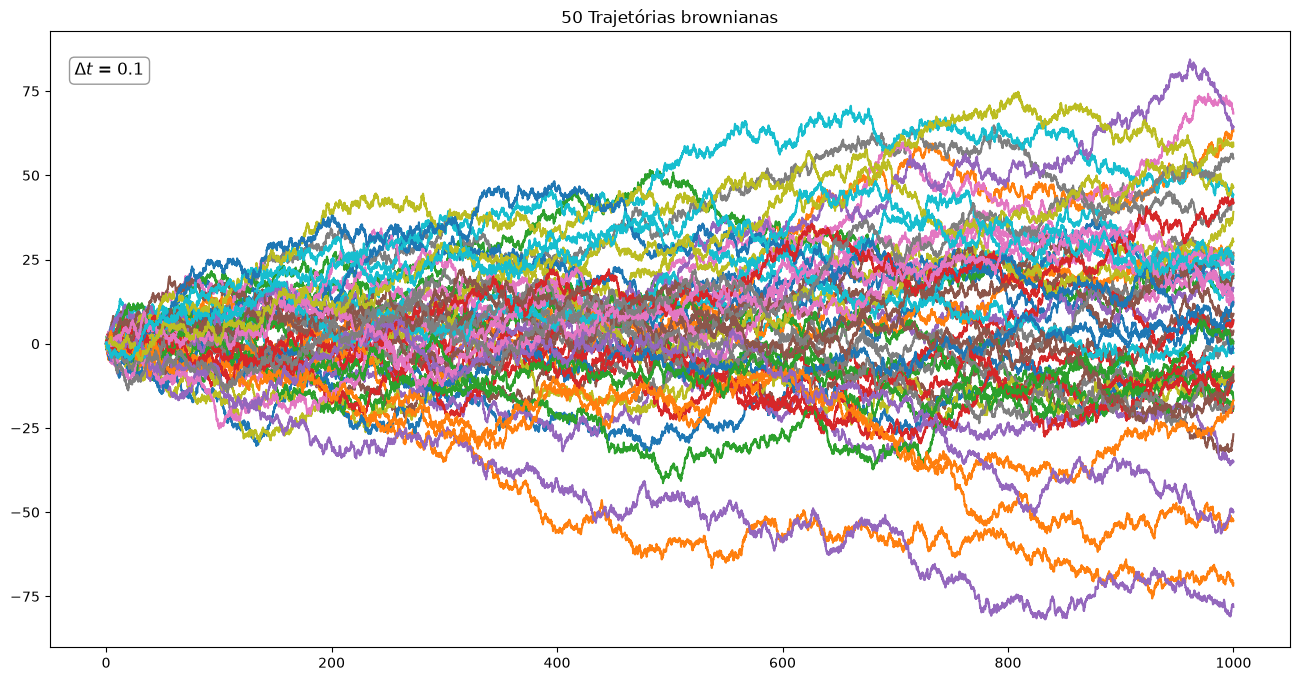

In [7]:
N = 50
plt.figure(figsize = (16,8))
plt.title(f"{N} Trajetórias brownianas")
plt.text(0.02,0.95, rf"$\Delta t $ = {delta_t}",
    transform=plt.gca().transAxes, # Usa coordenadas relativas ao gráfico (0 a 1)
    fontsize=12,
    verticalalignment='top',   # Alinha o topo da caixa no ponto y=0.95
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray') # Estilo da caixa
)
for _ in tqdm(range(N)):
    x, y = movimento_browniano(delta_t = delta_t, n = n)
    plt.plot(x,y)
plt.show()

# B)

## $$c * N(\mu, \sigma^2) \sim N(c\mu, c^2\sigma^2) $$

### Então:
$\frac{1}{2} N(-2,1) + \frac{1}{2} N(2,1) \sim N(0, \frac{1}{2}) $

$a(x) = \frac{d}{dx} \log{p(x)} =  $ <br>
Contas feitas na lousa do pet

$X_{k+1} = X_k - 8X_k \Delta t + \sqrt{2\Delta t}  Z_k$ <br>

In [35]:
ultimos_x = []
N = 1_000
a = lambda x: -4 * ((x+1) * np.exp(-2 * (x+1)**2) + (x-1) * np.exp(-2 * (x-1)**2))/ (np.exp(-2 * (x+1) ** 2) + np.exp(-2 * (x-1) ** 2))
for i in tqdm(range(N)):
    x, y = movimento_browniano(delta_t, n, a = a,  b = lambda x : 2 ** .5)
    ultimos_x.append(y[-1])

100%|██████████████████████████████████████| 1000/1000 [01:05<00:00, 15.22it/s]


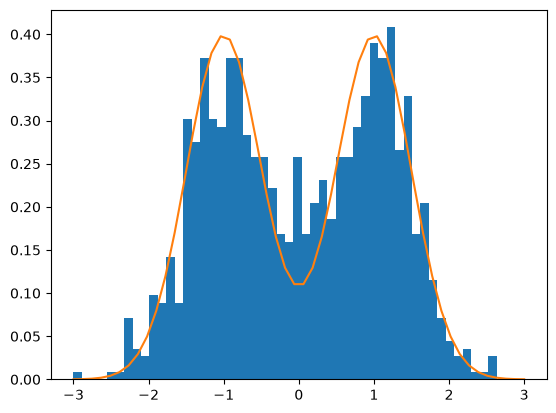

In [36]:
def p(x):
    return 1/(2 * np.pi) ** .5 * (np.exp(-2*(x+1) ** 2) + np.exp(-2 * (x-1) ** 2))
z = np.linspace(-3,3)
plt.hist(ultimos_x, bins = 50, density = True)
plt.plot(z, p(z))
plt.show()

In [37]:
ultimos_x = []
N = 1_000
T = 5_000
delta_t = T/n
a = lambda x: -4 * ((x+1) * np.exp(-2 * (x+1)**2) + (x-1) * np.exp(-2 * (x-1)**2))/ (np.exp(-2 * (x+1) ** 2) + np.exp(-2 * (x-1) ** 2))
for i in tqdm(range(N)):
    x, y = movimento_browniano(delta_t, n, a = a,  b = lambda x : 2 ** .5)
    ultimos_x.append(y[-1])

100%|██████████████████████████████████████| 1000/1000 [01:06<00:00, 15.12it/s]


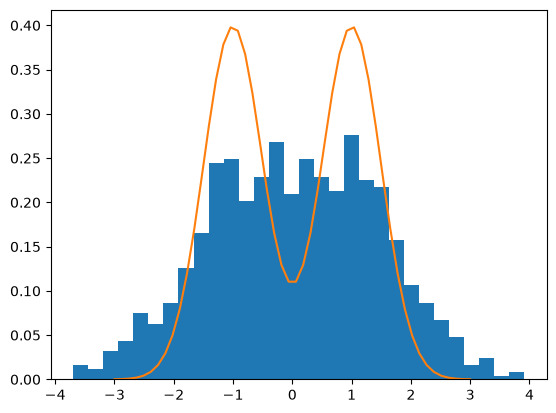

In [43]:
def p(x):
    return 1/(2 * np.pi) ** .5 * (np.exp(-2*(x+1) ** 2) + np.exp(-2 * (x-1) ** 2))
z = np.linspace(-3,3)
plt.hist(ultimos_x, bins = 30, density = True)
plt.plot(z, p(z))
plt.show()

## Repostas

i) O termo de deriva (a) faz com que o movimento seja limitado, não podendo chegar em valores extremos

ii) Diminuir o $\Delta t$ faz com que a precisão aumente, para um mesmo T

iii) 